# <center> Employee Retention Prediction <center>
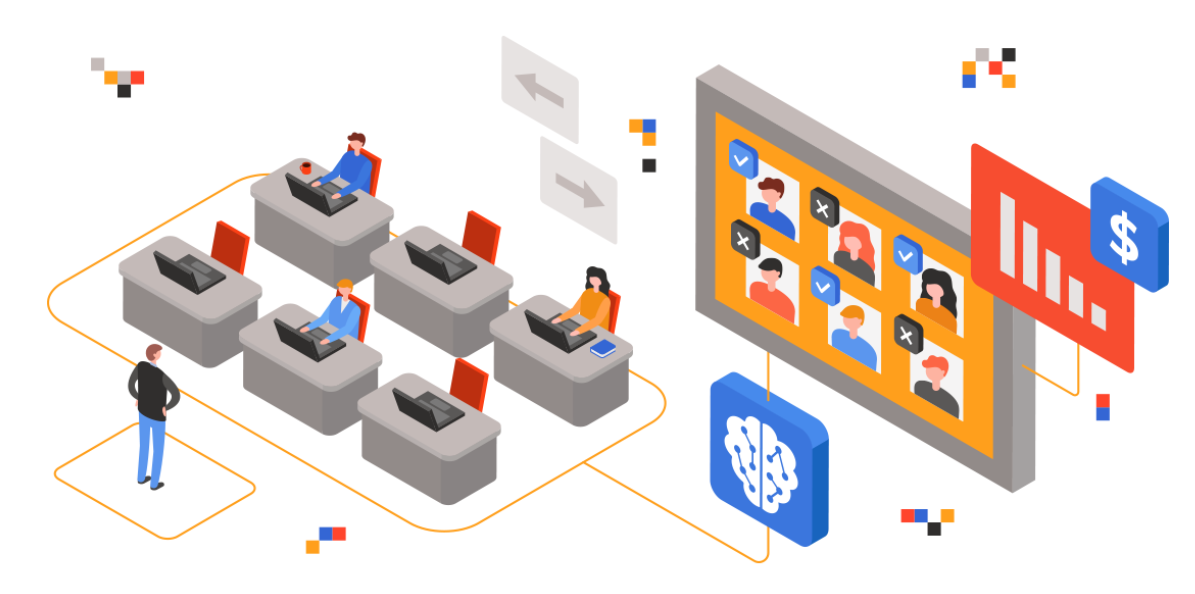

### Agenda:
1. [Frame the Problem / Business Case](#problem)
2. [Gathering the Data](#data)
3. [Data Pre-Pocessing](#processing)
4. [EDA](#eda)
5. [Feature Engineering](#engg)
6. [Model Training, Evaluation and Selection](#model)

<a id='problem'></a>

## 1. Frame the Problem / Business Case

### Background:
- Hiring and retaining employees are extremely complex tasks that require capital, time and skills
- Small business owners spend **40% of their working** hours on tasks that do **not** generate any income such as hiring
- Companies spend **15%-20%** of the employee's salary to recruit a new candidate
- An average company loses anywhere **between 1% and 2.5%** of their total revenue on the time it takes to bring a new hire up to speed
- It takes **52 days** on average to fill a position

### Problem Statement:
- You work as a data scientist at a Multi-National Corporation
- The HR team collected extensive data on their employees and approached you to develop a model that could predict which employees are more likely to quit
- The team provided you with an extensive dataset, a sample of which is provided: 
    - JobInvolvement
    - Education
    - JobSatisfaction
    - PerformanceRating
    - RelationshipSatisfaction
    - WorkLifeBalance

<a id='data'></a>

## 2. Gathering the Data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings

warnings.filterwarnings('ignore')
%matplotlib inline
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
pd.set_option('display.max_columns', None)

RANDOM_STATE = 42

In [2]:
df = pd.read_csv('Human_Resources.csv')
print(f"Dataset shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()

Dataset shape: 1470 rows, 35 columns


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


Let's look at the structure and data types of every column.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.923810,9.135373,18.0,30.00,36.0,43.00,60.0
DailyRate,1470.0,802.485714,403.509100,102.0,465.00,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.192517,8.106864,1.0,2.00,7.0,14.00,29.0
Education,1470.0,2.912925,1.024165,1.0,2.00,3.0,4.00,5.0
EmployeeCount,1470.0,1.000000,0.000000,1.0,1.00,1.0,1.00,1.0
EmployeeNumber,1470.0,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0
EnvironmentSatisfaction,1470.0,2.721769,1.093082,1.0,2.00,3.0,4.00,4.0
HourlyRate,1470.0,65.891156,20.329428,30.0,48.00,66.0,83.75,100.0
JobInvolvement,1470.0,2.729932,0.711561,1.0,2.00,3.0,3.00,4.0
JobLevel,1470.0,2.063946,1.106940,1.0,1.00,2.0,3.00,5.0


<a id='processing'></a>

## 3. Data Pre-Pocessing 

### 3.1 Missing Values & Duplicates

In [5]:
missing = df.isnull().sum()
print("Missing values per column:")
print(missing[missing > 0] if missing.sum() > 0 else "No missing values found.")

dup_count = df.duplicated().sum()
print(f"\nDuplicate rows: {dup_count}")

Missing values per column:
No missing values found.

Duplicate rows: 0


### 3.2 Identifying Non-Informative / Constant Columns
Some columns carry no predictive signal because every employee has the same value, or they act purely as identifiers.

In [6]:
for col in df.columns:
    n_unique = df[col].nunique()
    if n_unique == 1:
        print(f"{col}: constant value -> {df[col].unique()}")

EmployeeCount: constant value -> [1]
Over18: constant value -> <StringArray>
['Y']
Length: 1, dtype: str
StandardHours: constant value -> [80]


In [7]:
cols_to_drop = ['EmployeeCount', 'StandardHours', 'Over18', 'EmployeeNumber']
df.drop(columns=cols_to_drop, inplace=True)
print(f"Dropped {cols_to_drop}")
print(f"New shape: {df.shape}")

Dropped ['EmployeeCount', 'StandardHours', 'Over18', 'EmployeeNumber']
New shape: (1470, 31)


### 3.3 Target Variable Encoding
We'll keep the readable `Attrition` column for plotting, and add a numeric flag for analysis.

In [8]:
df['AttritionFlag'] = df['Attrition'].map({'Yes': 1, 'No': 0})
attrition_rate = df['AttritionFlag'].mean() * 100
print(f"Overall attrition rate: {attrition_rate:.2f}%")
df[['Attrition', 'AttritionFlag']].head()

Overall attrition rate: 16.12%


,Attrition,AttritionFlag
0,Yes,1
1,No,0
2,Yes,1
3,No,0
4,No,0


### 3.4 Categorical vs Numerical Columns

In [9]:
categorical_cols = df.select_dtypes(include='object').columns.tolist()
categorical_cols.remove('Attrition')
numerical_cols = df.select_dtypes(include=np.number).columns.tolist()
numerical_cols.remove('AttritionFlag')

print(f"Categorical columns ({len(categorical_cols)}): {categorical_cols}")
print(f"\nNumerical columns ({len(numerical_cols)}): {numerical_cols}")

Categorical columns (7): ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']

Numerical columns (23): ['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']


<a id='eda'></a>

## 4. Exploratory Data Analysis (EDA)

### 4.1 Target Distribution

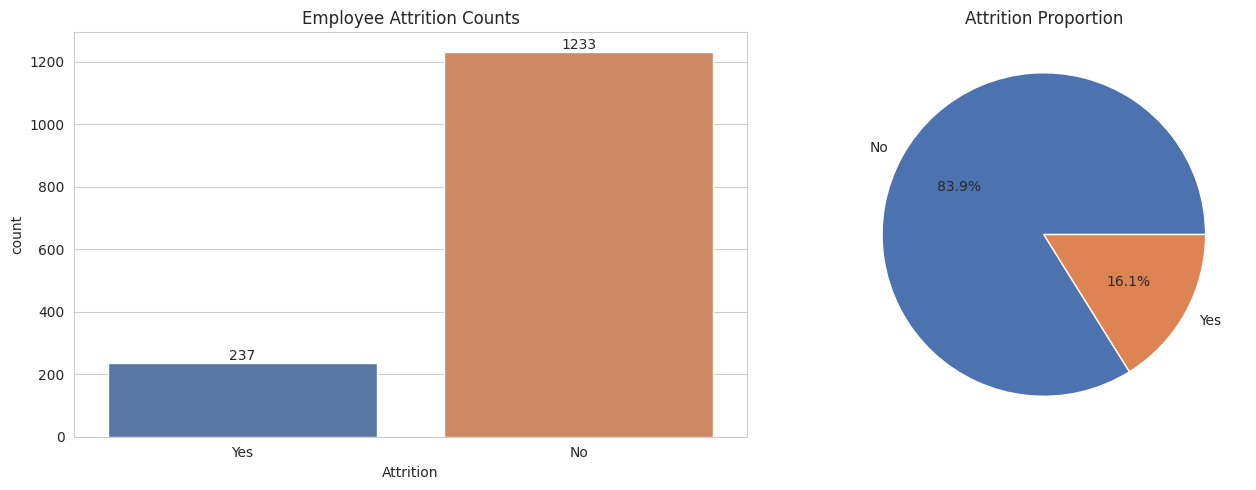

Class imbalance ratio (No:Yes) -> 1233:237

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=df, x='Attrition', palette=['#4C72B0', '#DD8452'], ax=axes[0])
axes[0].set_title('Employee Attrition Counts')
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width()/2, p.get_height()),
                      ha='center', va='bottom')

df['Attrition'].value_counts().plot.pie(autopct='%1.1f%%', colors=['#4C72B0', '#DD8452'],
                                         ax=axes[1], ylabel='')
axes[1].set_title('Attrition Proportion')

plt.tight_layout()
plt.show()

print(f"Class imbalance ratio (No:Yes) -> {(df['Attrition']=='No').sum()}:{(df['Attrition']=='Yes').sum()}")

**Observation:** The dataset is imbalanced -- roughly 84% of employees stayed and 16% left. This matters for model selection and evaluation metrics later (accuracy alone will be misleading).

### 4.2 Distribution of Numerical Features

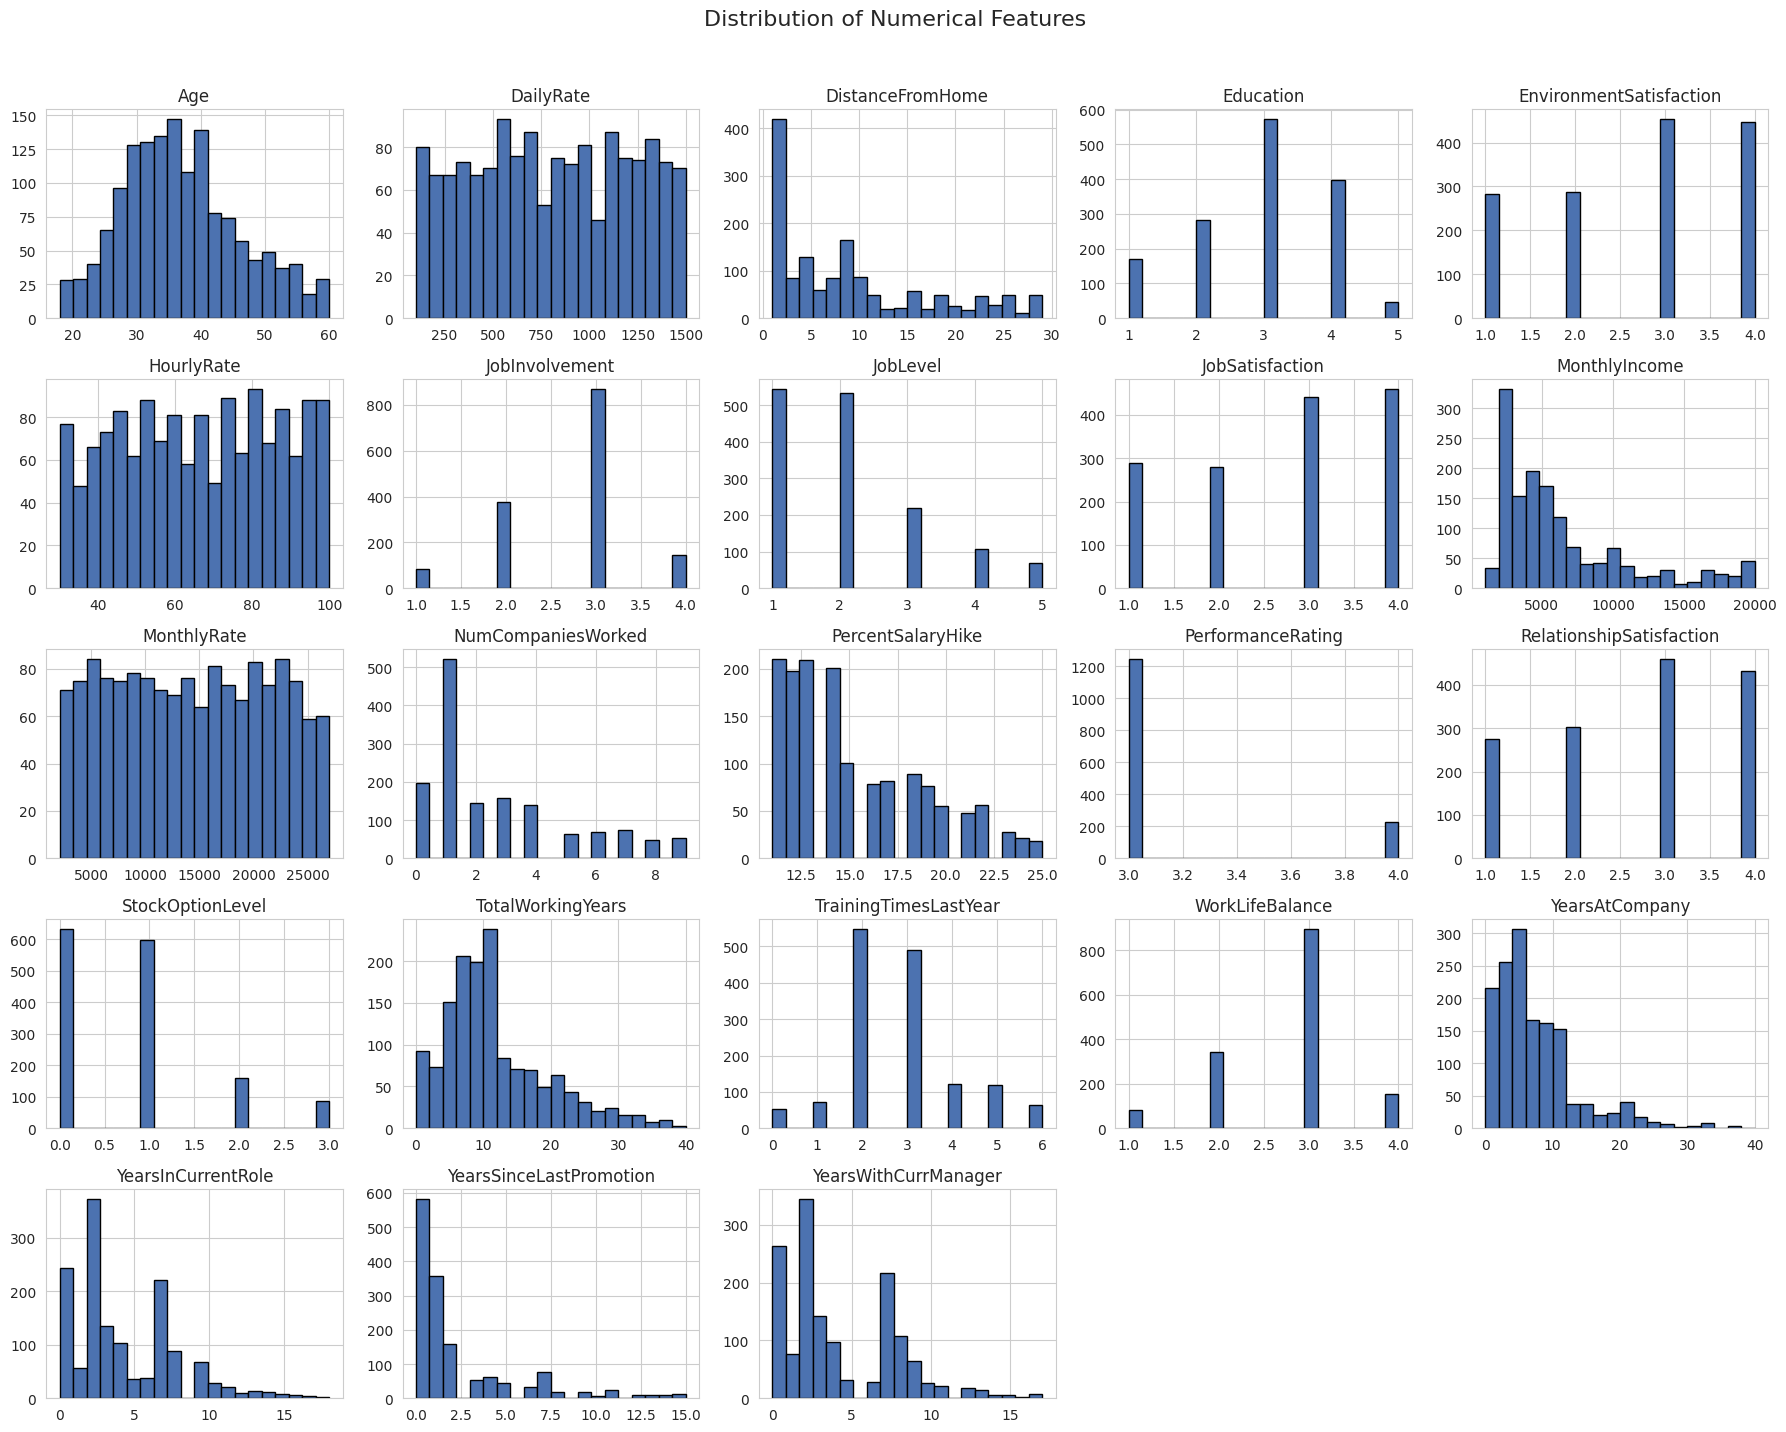

In [11]:
df[numerical_cols].hist(bins=20, figsize=(18, 14), color='#4C72B0', edgecolor='black')
plt.suptitle('Distribution of Numerical Features', y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

### 4.3 Correlation Heatmap

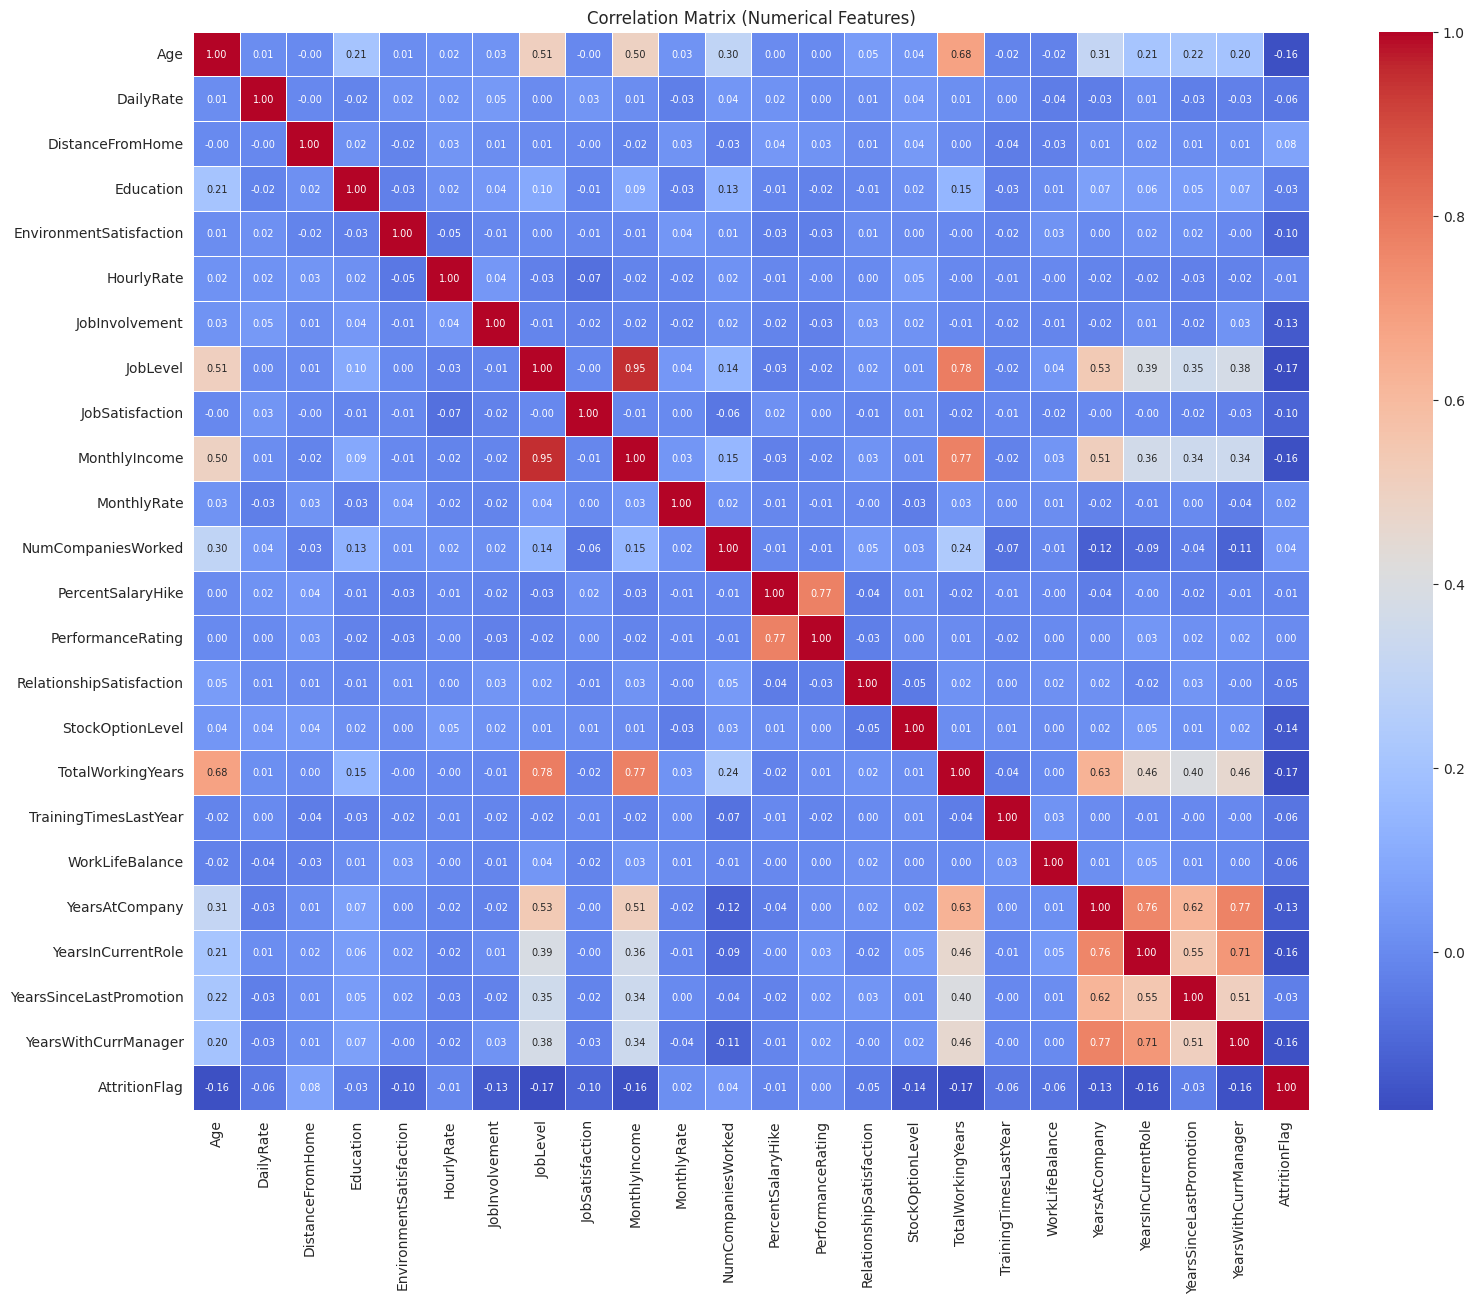

In [12]:
plt.figure(figsize=(18, 14))
corr = df[numerical_cols + ['AttritionFlag']].corr()
sns.heatmap(corr, cmap='coolwarm', annot=True, fmt='.2f', linewidths=0.5, annot_kws={'size': 7})
plt.title('Correlation Matrix (Numerical Features)')
plt.show()

In [13]:
corr_with_target = corr['AttritionFlag'].drop('AttritionFlag').sort_values(key=abs, ascending=False)
print("Features most correlated with Attrition:")
corr_with_target.head(10)

Features most correlated with Attrition:


TotalWorkingYears      -0.171063
JobLevel               -0.169105
YearsInCurrentRole     -0.160545
MonthlyIncome          -0.159840
Age                    -0.159205
YearsWithCurrManager   -0.156199
StockOptionLevel       -0.137145
YearsAtCompany         -0.134392
JobInvolvement         -0.130016
JobSatisfaction        -0.103481
Name: AttritionFlag, dtype: float64

### 4.4 Attrition vs. Categorical Features

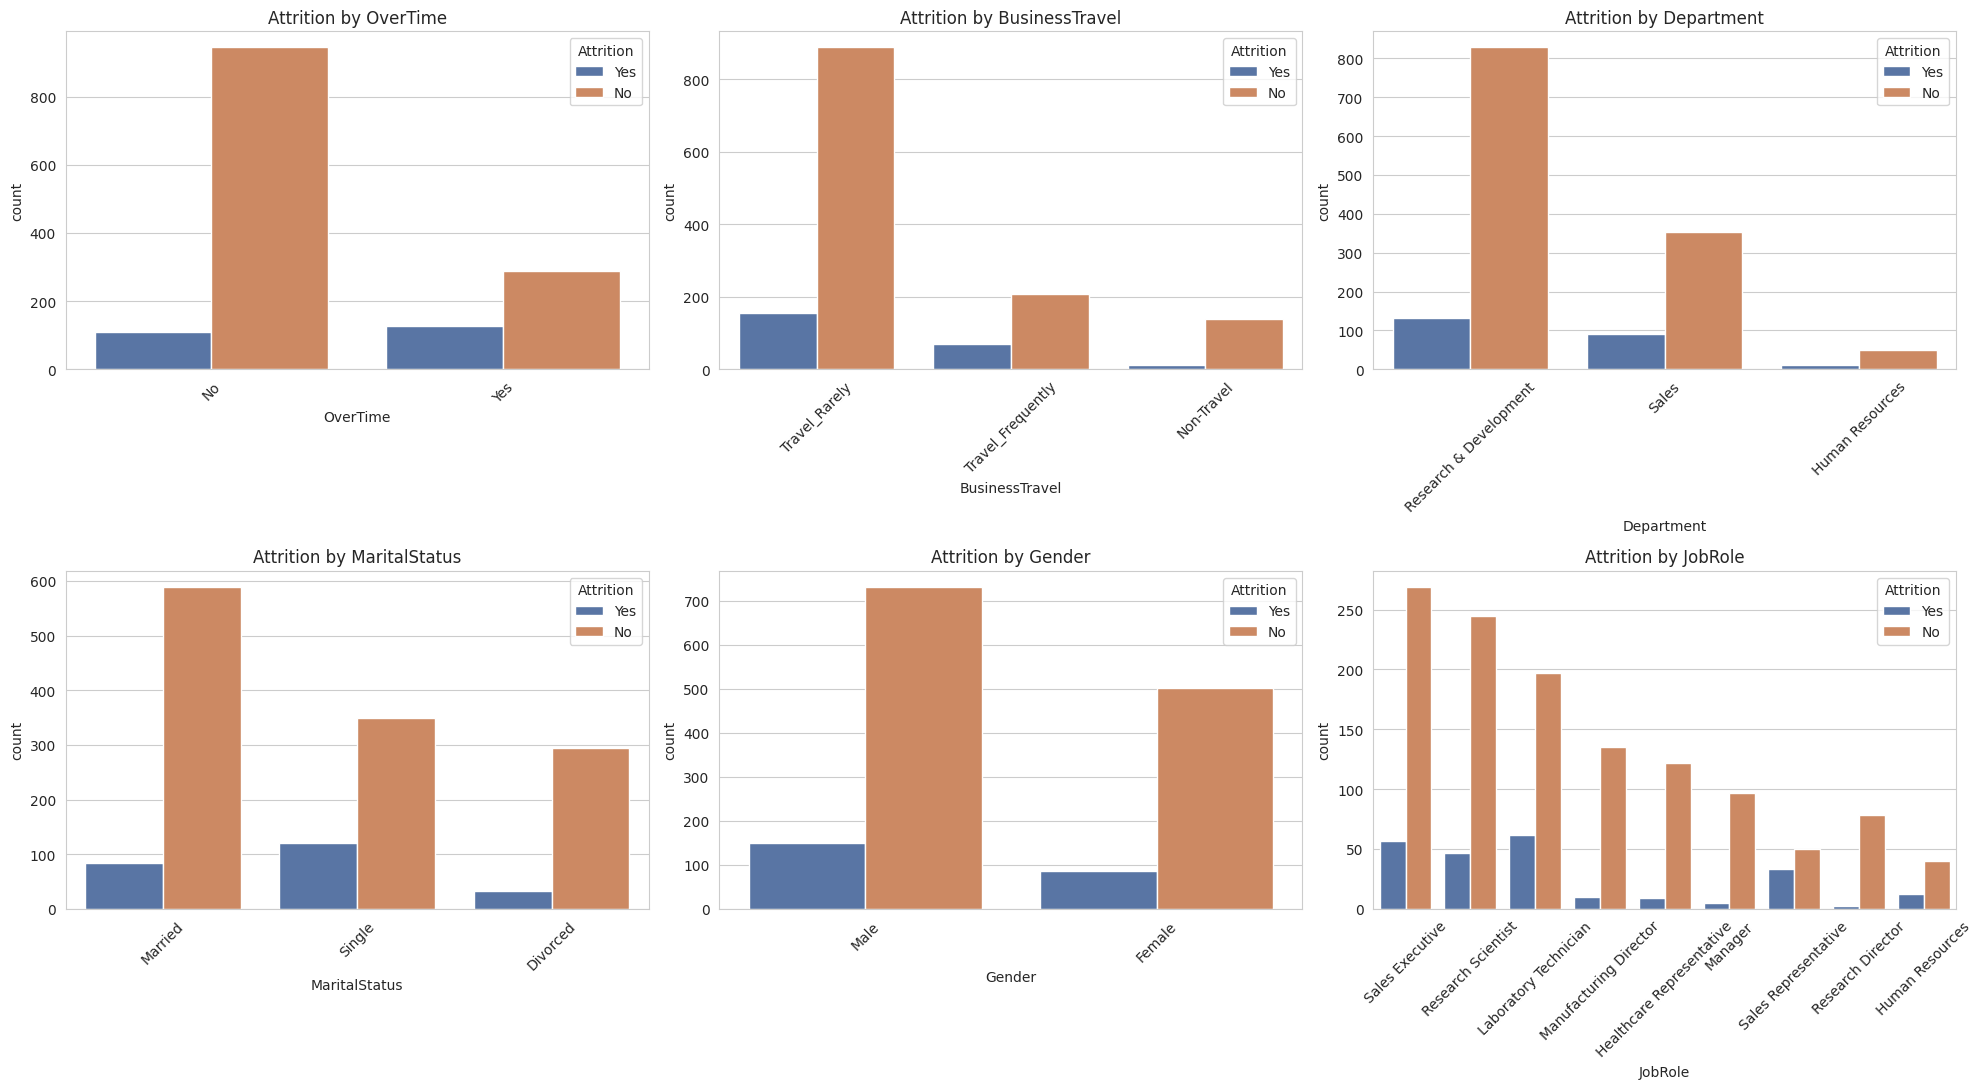

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(20, 11))
cat_plot_cols = ['OverTime', 'BusinessTravel', 'Department', 'MaritalStatus', 'Gender', 'JobRole']

for ax, col in zip(axes.flatten(), cat_plot_cols):
    order = df[col].value_counts().index
    sns.countplot(data=df, x=col, hue='Attrition', ax=ax, order=order,
                   palette=['#4C72B0', '#DD8452'])
    ax.set_title(f'Attrition by {col}')
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

**Observations:**
- Employees who work **OverTime** leave at a noticeably higher rate.
- **Frequent travelers** show higher attrition than those who rarely/never travel.
- **Sales Representatives** and **Laboratory Technicians** show elevated attrition among job roles.
- Single employees leave more often than married or divorced employees.

### 4.5 Attrition vs. Satisfaction / Rating Scores

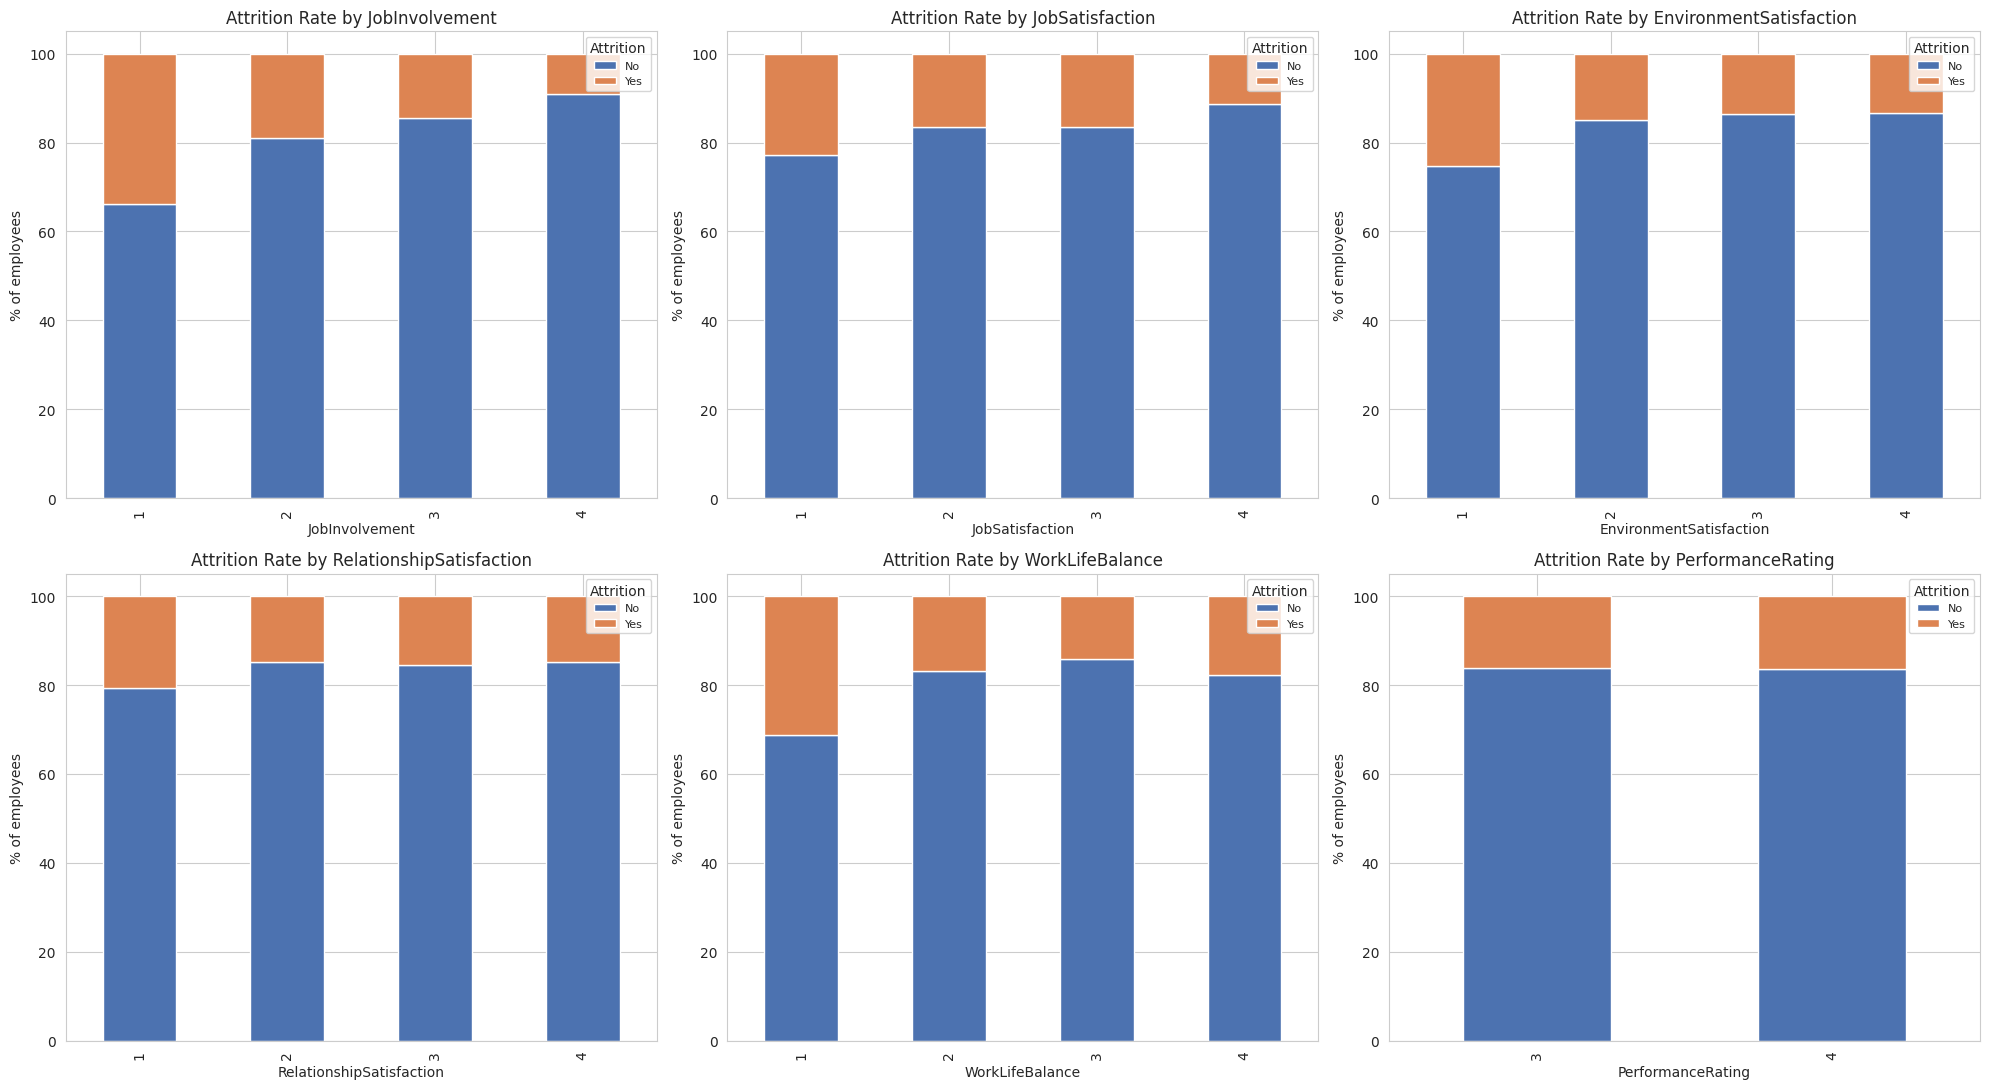

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(20, 11))
score_cols = ['JobInvolvement', 'JobSatisfaction', 'EnvironmentSatisfaction',
              'RelationshipSatisfaction', 'WorkLifeBalance', 'PerformanceRating']

for ax, col in zip(axes.flatten(), score_cols):
    ct = pd.crosstab(df[col], df['Attrition'], normalize='index') * 100
    ct.plot(kind='bar', stacked=True, ax=ax, color=['#4C72B0', '#DD8452'])
    ax.set_title(f'Attrition Rate by {col}')
    ax.set_ylabel('% of employees')
    ax.legend(title='Attrition', loc='upper right', fontsize=8)

plt.tight_layout()
plt.show()

**Observation:** Lower `JobInvolvement`, `JobSatisfaction`, `EnvironmentSatisfaction`, and `WorkLifeBalance` scores are associated with a higher proportion of attrition, while `PerformanceRating` shows little separation (most employees are rated similarly).

### 4.6 Attrition vs. Continuous Features

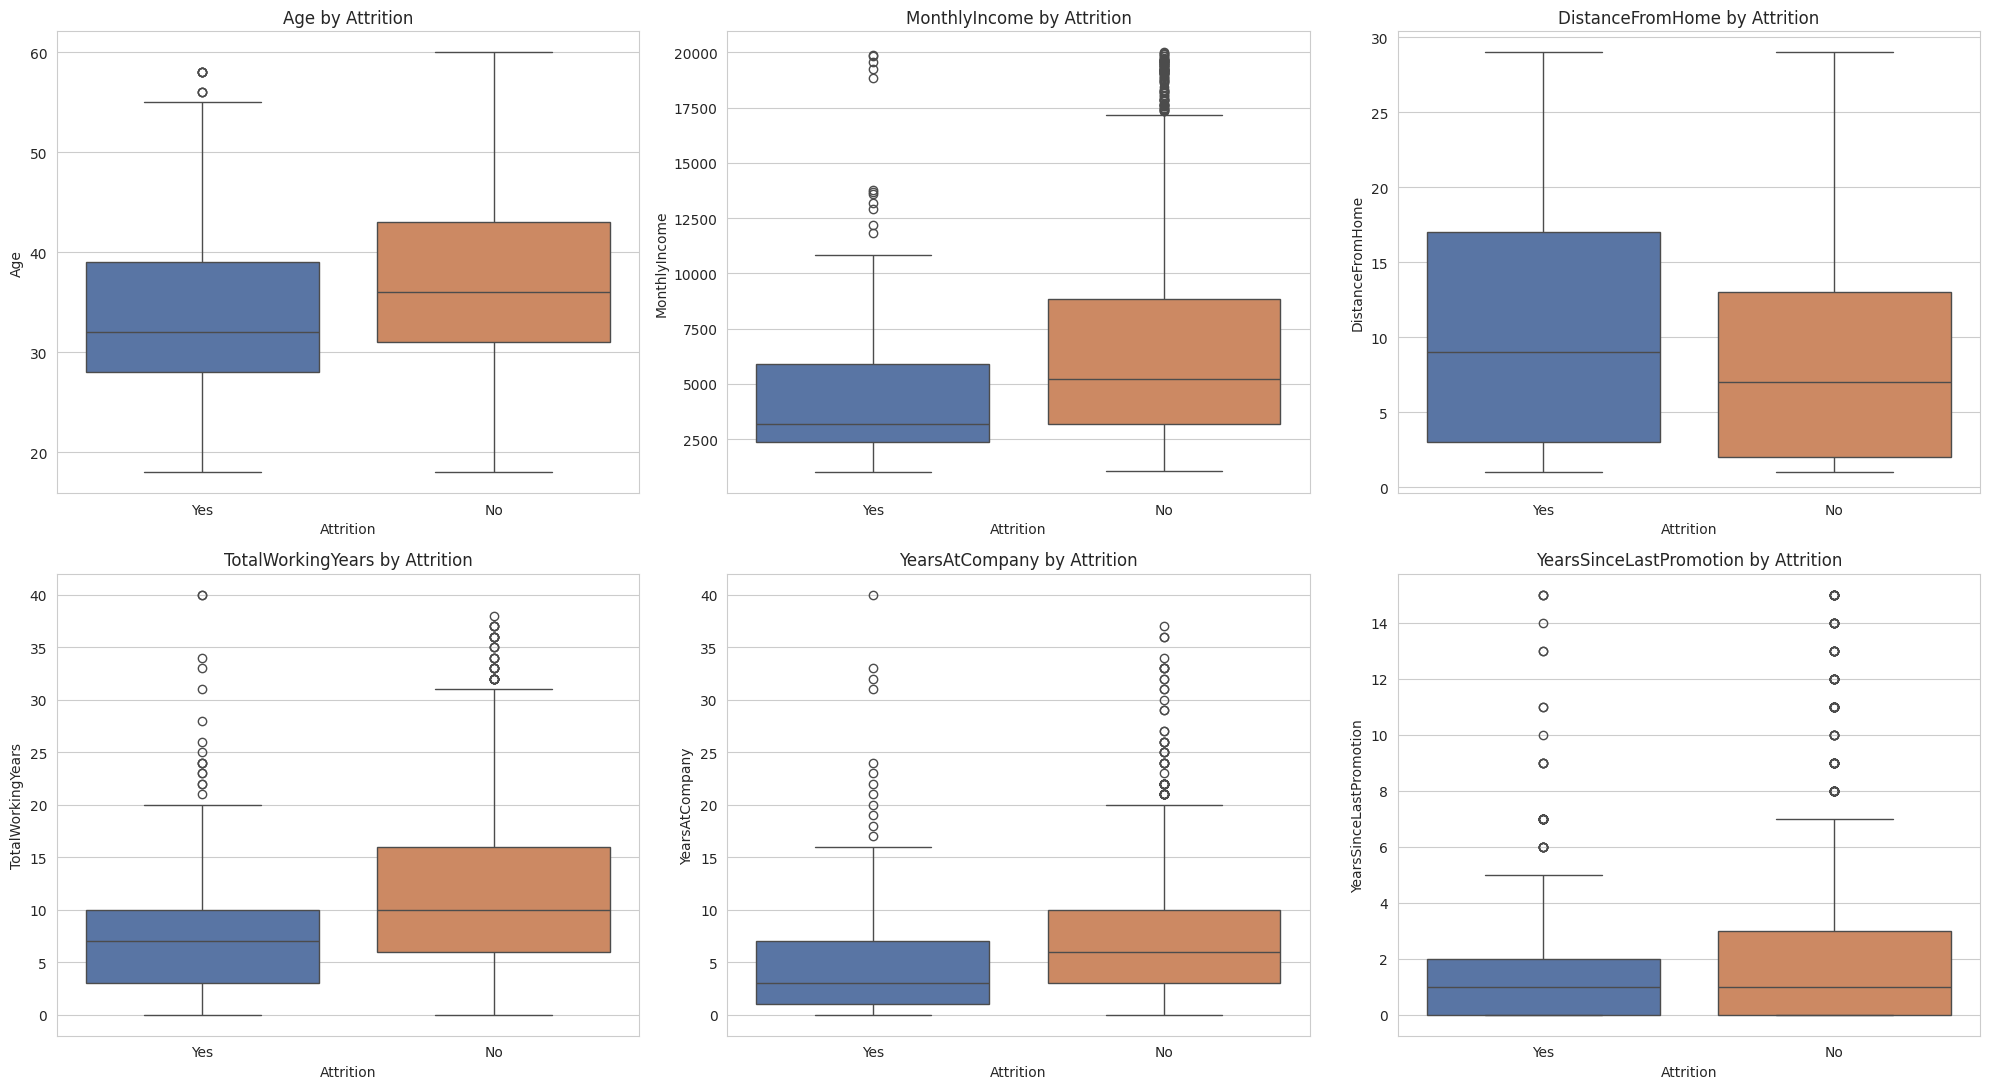

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(20, 11))
cont_cols = ['Age', 'MonthlyIncome', 'DistanceFromHome', 'TotalWorkingYears',
             'YearsAtCompany', 'YearsSinceLastPromotion']

for ax, col in zip(axes.flatten(), cont_cols):
    sns.boxplot(data=df, x='Attrition', y=col, ax=ax, palette=['#4C72B0', '#DD8452'])
    ax.set_title(f'{col} by Attrition')

plt.tight_layout()
plt.show()

**Observation:** Employees who leave tend to be **younger**, earn a **lower monthly income**, live **further from home**, and have **fewer total working years / years at the company** -- consistent with early-career or newly-hired employees being the highest flight risk.

### 4.7 EDA Summary
- The target is imbalanced (~16% attrition), so evaluation should rely on precision/recall/F1/ROC-AUC, not just accuracy.
- Strongest signals so far: `OverTime`, `MonthlyIncome`, `Age`, `TotalWorkingYears`, `YearsAtCompany`, `JobLevel`, `StockOptionLevel`, and the satisfaction/involvement scores.
- Business travel frequency, marital status, and job role also show meaningful differences in attrition rate.

<a id='engg'></a>

## 5. Feature Engineering

### 5.1 Encoding Categorical Variables

In [17]:
df_model = df.drop(columns=['Attrition']).copy()  # keep AttritionFlag as target

binary_cols = ['Gender', 'OverTime']
for col in binary_cols:
    df_model[col] = df_model[col].map({df_model[col].unique()[0]: 0, df_model[col].unique()[1]: 1}) \
        if set(df_model[col].unique()) != {'Yes', 'No'} else df_model[col].map({'No': 0, 'Yes': 1})

# Explicit, unambiguous mapping (overrides the heuristic above for clarity)
df_model['Gender'] = df['Gender'].map({'Male': 1, 'Female': 0})
df_model['OverTime'] = df['OverTime'].map({'Yes': 1, 'No': 0})

multi_cat_cols = ['BusinessTravel', 'Department', 'EducationField', 'JobRole', 'MaritalStatus']
df_model = pd.get_dummies(df_model, columns=multi_cat_cols, drop_first=True)

print(f"Shape after encoding: {df_model.shape}")
df_model.head()

Shape after encoding: (1470, 45)


,Age,DailyRate,DistanceFromHome,Education,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,MonthlyIncome,MonthlyRate,NumCompaniesWorked,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,AttritionFlag,BusinessTravel_Travel_Frequently,BusinessTravel_Travel_Rarely,Department_Research & Development,Department_Sales,EducationField_Life Sciences,EducationField_Marketing,EducationField_Medical,EducationField_Other,EducationField_Technical Degree,JobRole_Human Resources,JobRole_Laboratory Technician,JobRole_Manager,JobRole_Manufacturing Director,JobRole_Research Director,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative,MaritalStatus_Married,MaritalStatus_Single
0,41,1102,1,2,2,0,94,3,2,4,5993,19479,8,1,11,3,1,0,8,0,1,6,4,0,5,1,False,True,False,True,True,False,False,False,False,False,False,False,False,False,False,True,False,False,True
1,49,279,8,1,3,1,61,2,2,2,5130,24907,1,0,23,4,4,1,10,3,3,10,7,1,7,0,True,False,True,False,True,False,False,False,False,False,False,False,False,False,True,False,False,True,False
2,37,1373,2,2,4,1,92,2,1,3,2090,2396,6,1,15,3,2,0,7,3,3,0,0,0,0,1,False,True,True,False,False,False,False,True,False,False,True,False,False,False,False,False,False,False,True
3,33,1392,3,4,4,0,56,3,1,3,2909,23159,1,1,11,3,3,0,8,3,3,8,7,3,0,0,True,False,True,False,True,False,False,False,False,False,False,False,False,False,True,False,False,True,False
4,27,591,2,1,1,1,40,3,1,2,3468,16632,9,0,12,3,4,1,6,3,3,2,2,2,2,0,False,True,True,False,False,False,True,False,False,False,True,False,False,False,False,False,False,True,False


### 5.2 Train / Test Split

In [18]:
from sklearn.model_selection import train_test_split

X = df_model.drop(columns=['AttritionFlag'])
y = df_model['AttritionFlag']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print(f"Train shape: {X_train.shape}, Test shape: {X_test.shape}")
print(f"Train attrition rate: {y_train.mean():.2%}  |  Test attrition rate: {y_test.mean():.2%}")

Train shape: (1176, 44), Test shape: (294, 44)
Train attrition rate: 16.16%  |  Test attrition rate: 15.99%


### 5.3 Feature Scaling

In [19]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

X_train_scaled.head()

,Age,DailyRate,DistanceFromHome,Education,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,MonthlyIncome,MonthlyRate,NumCompaniesWorked,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,BusinessTravel_Travel_Frequently,BusinessTravel_Travel_Rarely,Department_Research & Development,Department_Sales,EducationField_Life Sciences,EducationField_Marketing,EducationField_Medical,EducationField_Other,EducationField_Technical Degree,JobRole_Human Resources,JobRole_Laboratory Technician,JobRole_Manager,JobRole_Manufacturing Director,JobRole_Research Director,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative,MaritalStatus_Married,MaritalStatus_Single
1194,1.090194,1.049455,-0.899915,1.064209,-0.658710,-1.221280,-0.908436,1.795282,1.762189,-0.647997,2.026752,0.931289,1.330763,-0.637729,-0.337129,-0.432065,0.240218,2.613100,2.261482,-0.605389,0.337621,-0.665706,-0.625365,-0.368024,-0.616406,-0.486408,0.648298,-1.361752,1.493576,1.206281,-0.358607,-0.669534,-0.235914,-0.329224,-0.190061,-0.472996,3.628867,-0.326041,-0.237915,-0.479714,-0.549841,-0.231869,-0.921443,-0.681548
128,-1.634828,-0.523449,-0.899915,-1.855332,0.260202,0.818813,1.694111,0.373564,-0.986265,1.153526,-0.864408,0.682742,-1.083704,-0.637729,-0.337129,-0.432065,0.240218,0.247430,-1.072675,-0.605389,0.337621,-0.830071,-0.905635,-0.056884,-0.897047,-0.486408,0.648298,0.734348,-0.669534,-0.828994,-0.358607,-0.669534,-0.235914,3.037447,-0.190061,2.114182,-0.275568,-0.326041,-0.237915,-0.479714,-0.549841,-0.231869,1.085255,-0.681548
810,0.981193,-0.992080,-0.777610,-1.855332,-1.577622,0.818813,-0.662913,0.373564,1.762189,0.252765,2.347706,0.167705,0.123529,-0.637729,-0.880974,-0.432065,1.160403,0.247430,1.492061,0.190962,0.337621,0.813578,1.336527,0.565398,1.348076,-0.486408,0.648298,-1.361752,1.493576,-0.828994,2.788569,-0.669534,-0.235914,-0.329224,-0.190061,-0.472996,3.628867,-0.326041,-0.237915,-0.479714,-0.549841,-0.231869,1.085255,-0.681548
478,-1.307825,-0.453653,0.445433,-1.855332,-0.658710,0.818813,-1.252169,0.373564,-0.986265,0.252765,-0.956202,1.667056,-0.681293,-0.637729,-1.152896,-0.432065,0.240218,-0.935405,-0.559727,-1.401740,0.337621,-0.008246,-0.064824,-0.679165,0.506155,-0.486408,0.648298,-1.361752,1.493576,-0.828994,-0.358607,1.493576,-0.235914,-0.329224,-0.190061,-0.472996,-0.275568,-0.326041,-0.237915,-0.479714,-0.549841,4.312772,1.085255,-0.681548
491,0.654191,0.491086,-0.043784,2.037390,1.179114,0.818813,0.319180,0.373564,-0.070114,0.252765,-0.185956,0.728362,0.123529,1.568064,-0.609051,-0.432065,-0.679966,0.247430,-0.175017,0.190962,0.337621,0.156119,0.775986,0.565398,0.786795,2.055886,-1.542501,0.734348,-0.669534,-0.828994,-0.358607,1.493576,-0.235914,-0.329224,-0.190061,2.114182,-0.275568,-0.326041,-0.237915,-0.479714,-0.549841,-0.231869,-0.921443,-0.681548


### 5.4 Handling Class Imbalance
We address the ~16% vs 84% imbalance with **SMOTE** (Synthetic Minority Over-sampling) on the training set only, so the test set stays representative of real-world class proportions.

In [20]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=RANDOM_STATE)
X_train_res, y_train_res = smote.fit_resample(X_train_scaled, y_train)

print("Before SMOTE:", y_train.value_counts().to_dict())
print("After SMOTE :", y_train_res.value_counts().to_dict())

Before SMOTE: {0: 986, 1: 190}
After SMOTE : {0: 986, 1: 986}


<a id='model'></a>

## 6. Model Training, Evaluation and Selection

### 6.1 Imports & Evaluation Helper

In [21]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, roc_curve, confusion_matrix, classification_report)

results = {}

def evaluate_model(name, model, X_tr, y_tr, X_te, y_te):
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)
    y_proba = model.predict_proba(X_te)[:, 1] if hasattr(model, 'predict_proba') else model.decision_function(X_te)

    metrics = {
        'Accuracy': accuracy_score(y_te, y_pred),
        'Precision': precision_score(y_te, y_pred),
        'Recall': recall_score(y_te, y_pred),
        'F1 Score': f1_score(y_te, y_pred),
        'ROC AUC': roc_auc_score(y_te, y_proba)
    }
    results[name] = metrics
    print(f"--- {name} ---")
    for k, v in metrics.items():
        print(f"{k}: {v:.4f}")
    print()
    return model, y_pred, y_proba

### 6.2 Logistic Regression (baseline)

In [22]:
log_reg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
log_reg, y_pred_lr, y_proba_lr = evaluate_model('Logistic Regression', log_reg,
                                                  X_train_res, y_train_res, X_test_scaled, y_test)

--- Logistic Regression ---
Accuracy: 0.7755
Precision: 0.3733
Recall: 0.5957
F1 Score: 0.4590
ROC AUC: 0.7854



### 6.3 Decision Tree

In [23]:
dtree = DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE)
dtree, y_pred_dt, y_proba_dt = evaluate_model('Decision Tree', dtree,
                                                X_train_res, y_train_res, X_test_scaled, y_test)

--- Decision Tree ---
Accuracy: 0.8129
Precision: 0.4167
Recall: 0.4255
F1 Score: 0.4211
ROC AUC: 0.6877



### 6.4 Random Forest

In [24]:
rf = RandomForestClassifier(n_estimators=300, max_depth=8, random_state=RANDOM_STATE, n_jobs=-1)
rf, y_pred_rf, y_proba_rf = evaluate_model('Random Forest', rf,
                                             X_train_res, y_train_res, X_test_scaled, y_test)

--- Random Forest ---
Accuracy: 0.8503
Precision: 0.5517
Recall: 0.3404
F1 Score: 0.4211
ROC AUC: 0.8021



### 6.5 Gradient Boosting

In [25]:
gb = GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=3, random_state=RANDOM_STATE)
gb, y_pred_gb, y_proba_gb = evaluate_model('Gradient Boosting', gb,
                                             X_train_res, y_train_res, X_test_scaled, y_test)

--- Gradient Boosting ---
Accuracy: 0.8571
Precision: 0.5758
Recall: 0.4043
F1 Score: 0.4750
ROC AUC: 0.8031



### 6.6 XGBoost

In [26]:
xgb = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                     random_state=RANDOM_STATE, eval_metric='logloss', use_label_encoder=False)
xgb, y_pred_xgb, y_proba_xgb = evaluate_model('XGBoost', xgb,
                                                X_train_res, y_train_res, X_test_scaled, y_test)

--- XGBoost ---
Accuracy: 0.8605
Precision: 0.6500
Recall: 0.2766
F1 Score: 0.3881
ROC AUC: 0.7930



### 6.7 Support Vector Machine

In [27]:
svm = SVC(kernel='rbf', probability=True, random_state=RANDOM_STATE)
svm, y_pred_svm, y_proba_svm = evaluate_model('SVM (RBF)', svm,
                                                X_train_res, y_train_res, X_test_scaled, y_test)

--- SVM (RBF) ---
Accuracy: 0.8197
Precision: 0.4211
Recall: 0.3404
F1 Score: 0.3765
ROC AUC: 0.7185



### 6.8 Model Comparison

In [28]:
results_df = pd.DataFrame(results).T.sort_values('ROC AUC', ascending=False)
results_df.style.background_gradient(cmap='Blues')

,Accuracy,Precision,Recall,F1 Score,ROC AUC
Gradient Boosting,0.857143,0.575758,0.404255,0.475000,0.803084
Random Forest,0.850340,0.551724,0.340426,0.421053,0.802136
XGBoost,0.860544,0.650000,0.276596,0.388060,0.793005
Logistic Regression,0.775510,0.373333,0.595745,0.459016,0.785425
SVM (RBF),0.819728,0.421053,0.340426,0.376471,0.718494
Decision Tree,0.812925,0.416667,0.425532,0.421053,0.687656


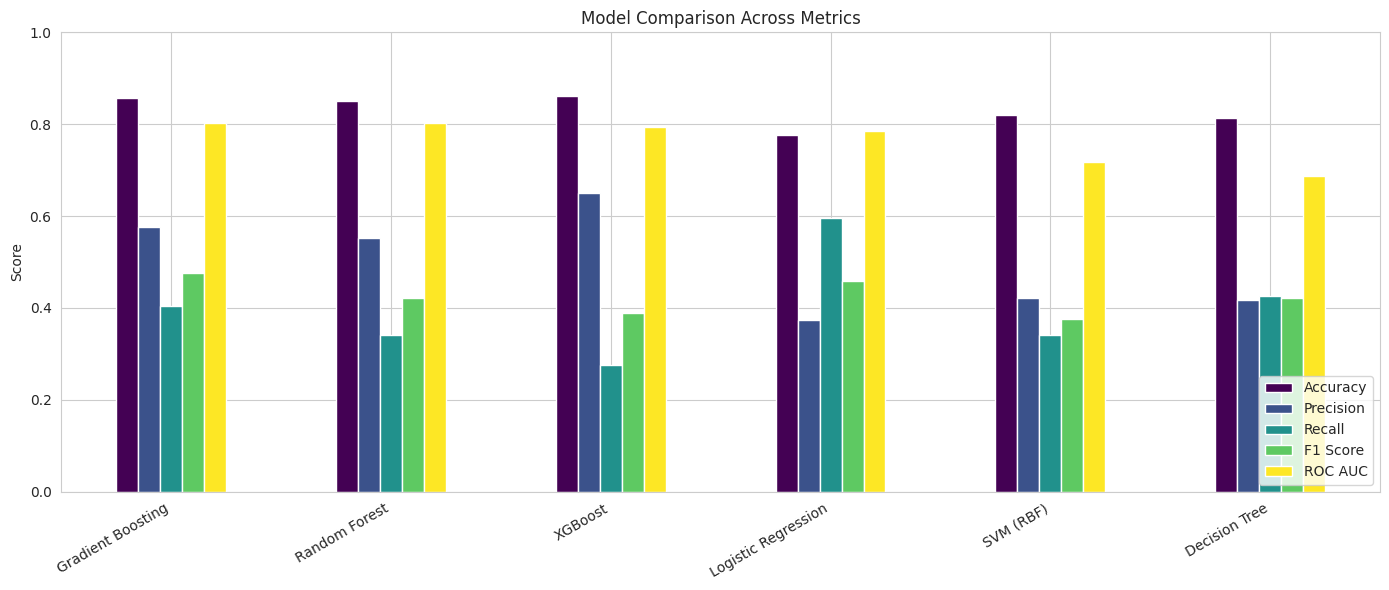

In [29]:
results_df[['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC AUC']].plot(
    kind='bar', figsize=(14, 6), colormap='viridis')
plt.title('Model Comparison Across Metrics')
plt.ylabel('Score')
plt.xticks(rotation=30, ha='right')
plt.ylim(0, 1)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

### 6.9 ROC Curves

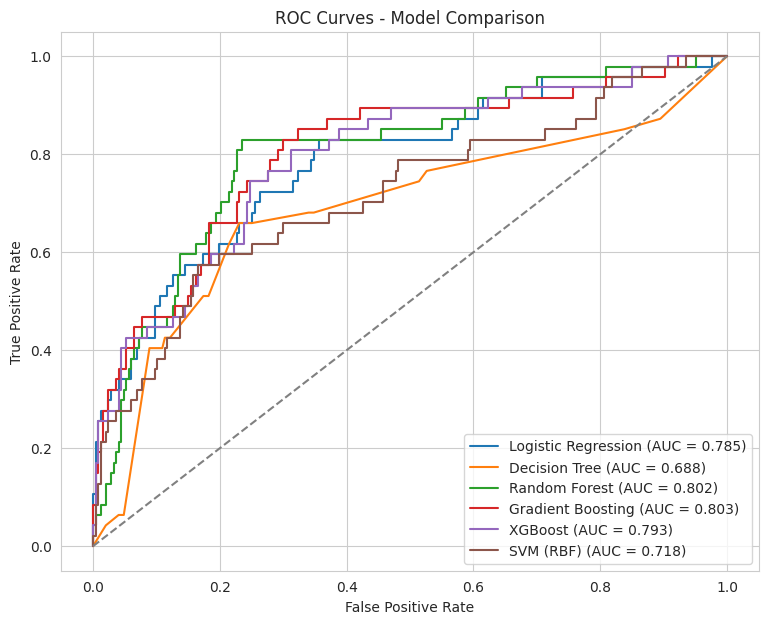

In [30]:
plt.figure(figsize=(9, 7))
proba_map = {
    'Logistic Regression': y_proba_lr,
    'Decision Tree': y_proba_dt,
    'Random Forest': y_proba_rf,
    'Gradient Boosting': y_proba_gb,
    'XGBoost': y_proba_xgb,
    'SVM (RBF)': y_proba_svm,
}

for name, proba in proba_map.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})')

plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves - Model Comparison')
plt.legend(loc='lower right')
plt.show()

### 6.10 Selecting the Best Model
We select the model with the highest **ROC-AUC** as the primary criterion, since it best reflects performance on an imbalanced target, while also checking **Recall** for the attrition class -- missing an employee who is about to leave is the costlier business error.

In [31]:
best_model_name = results_df['ROC AUC'].idxmax()
print(f"Best model by ROC AUC: {best_model_name}")
results_df.loc[[best_model_name]]

Best model by ROC AUC: Gradient Boosting


,Accuracy,Precision,Recall,F1 Score,ROC AUC
Gradient Boosting,0.857143,0.575758,0.404255,0.475,0.803084


### 6.11 Confusion Matrix & Classification Report (Best Model)

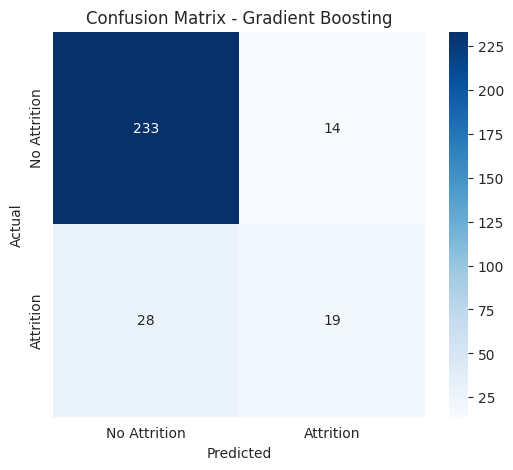

              precision    recall  f1-score   support

No Attrition       0.89      0.94      0.92       247
   Attrition       0.58      0.40      0.47        47

    accuracy                           0.86       294
   macro avg       0.73      0.67      0.70       294
weighted avg       0.84      0.86      0.85       294



In [32]:
pred_map = {
    'Logistic Regression': y_pred_lr,
    'Decision Tree': y_pred_dt,
    'Random Forest': y_pred_rf,
    'Gradient Boosting': y_pred_gb,
    'XGBoost': y_pred_xgb,
    'SVM (RBF)': y_pred_svm,
}
best_pred = pred_map[best_model_name]

cm = confusion_matrix(y_test, best_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Attrition', 'Attrition'],
            yticklabels=['No Attrition', 'Attrition'])
plt.title(f'Confusion Matrix - {best_model_name}')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

print(classification_report(y_test, best_pred, target_names=['No Attrition', 'Attrition']))

### 6.12 Hyperparameter Tuning (Best Model)

In [33]:
from sklearn.model_selection import GridSearchCV

model_map = {
    'Logistic Regression': (LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
                             {'C': [0.01, 0.1, 1, 10]}),
    'Random Forest': (RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
                       {'n_estimators': [200, 400], 'max_depth': [6, 8, 10]}),
    'Gradient Boosting': (GradientBoostingClassifier(random_state=RANDOM_STATE),
                           {'n_estimators': [150, 300], 'learning_rate': [0.03, 0.05, 0.1], 'max_depth': [2, 3]}),
    'XGBoost': (XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss', use_label_encoder=False),
                {'n_estimators': [150, 300], 'learning_rate': [0.03, 0.05, 0.1], 'max_depth': [3, 4, 5]}),
    'Decision Tree': (DecisionTreeClassifier(random_state=RANDOM_STATE),
                       {'max_depth': [4, 6, 8], 'min_samples_leaf': [1, 5, 10]}),
    'SVM (RBF)': (SVC(kernel='rbf', probability=True, random_state=RANDOM_STATE),
                  {'C': [0.5, 1, 5], 'gamma': ['scale', 'auto']}),
}

base_model, param_grid = model_map[best_model_name]

grid = GridSearchCV(base_model, param_grid, scoring='roc_auc', cv=5, n_jobs=-1)
grid.fit(X_train_res, y_train_res)

print(f"Best params for {best_model_name}: {grid.best_params_}")
print(f"Best CV ROC-AUC: {grid.best_score_:.4f}")

Best params for Gradient Boosting: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 300}
Best CV ROC-AUC: 0.9748


### 6.13 Final Model Evaluation

--- Gradient Boosting (Tuned) ---
Accuracy: 0.8639
Precision: 0.6296
Recall: 0.3617
F1 Score: 0.4595
ROC AUC: 0.8114



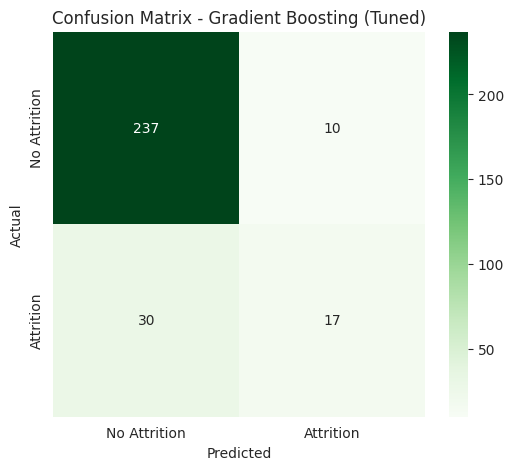

              precision    recall  f1-score   support

No Attrition       0.89      0.96      0.92       247
   Attrition       0.63      0.36      0.46        47

    accuracy                           0.86       294
   macro avg       0.76      0.66      0.69       294
weighted avg       0.85      0.86      0.85       294



In [34]:
tuned_model = grid.best_estimator_
tuned_model, y_pred_tuned, y_proba_tuned = evaluate_model(f'{best_model_name} (Tuned)', tuned_model,
                                                            X_train_res, y_train_res, X_test_scaled, y_test)

cm_tuned = confusion_matrix(y_test, y_pred_tuned)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_tuned, annot=True, fmt='d', cmap='Greens',
            xticklabels=['No Attrition', 'Attrition'],
            yticklabels=['No Attrition', 'Attrition'])
plt.title(f'Confusion Matrix - {best_model_name} (Tuned)')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

print(classification_report(y_test, y_pred_tuned, target_names=['No Attrition', 'Attrition']))

### 6.14 Feature Importance

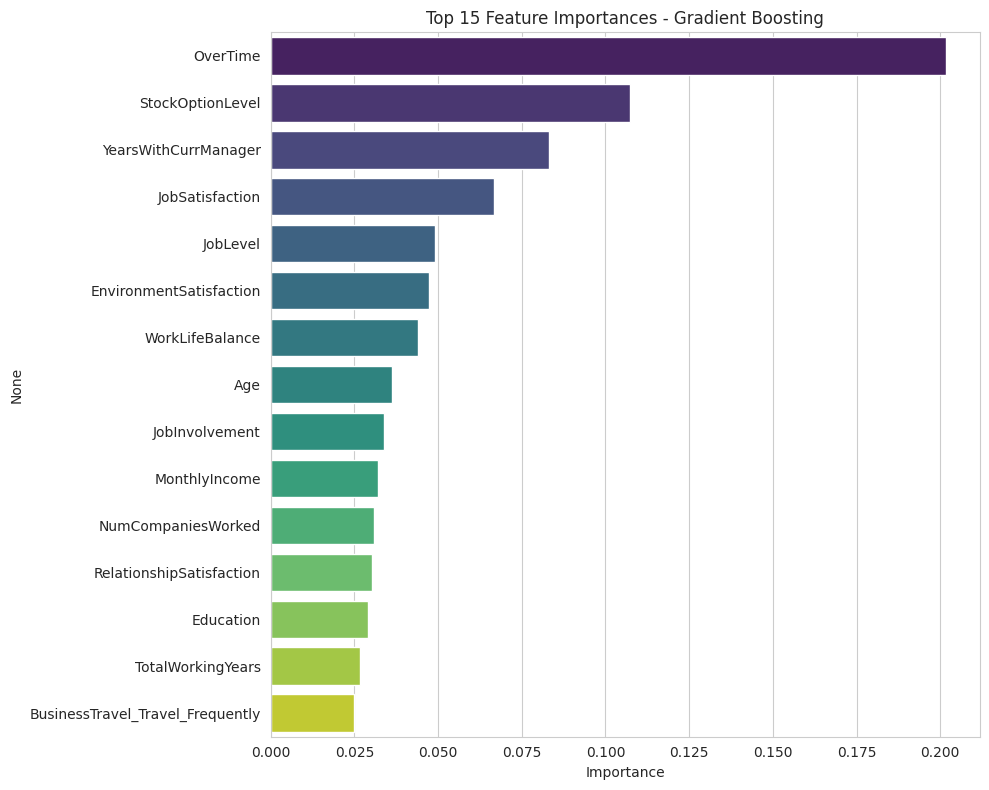

In [35]:
if hasattr(tuned_model, 'feature_importances_'):
    importances = pd.Series(tuned_model.feature_importances_, index=X_train.columns)
    importances = importances.sort_values(ascending=False).head(15)

    plt.figure(figsize=(10, 8))
    sns.barplot(x=importances.values, y=importances.index, palette='viridis')
    plt.title(f'Top 15 Feature Importances - {best_model_name}')
    plt.xlabel('Importance')
    plt.tight_layout()
    plt.show()
elif hasattr(tuned_model, 'coef_'):
    importances = pd.Series(tuned_model.coef_[0], index=X_train.columns)
    importances = importances.reindex(importances.abs().sort_values(ascending=False).index).head(15)

    plt.figure(figsize=(10, 8))
    colors = ['#DD8452' if v > 0 else '#4C72B0' for v in importances.values]
    sns.barplot(x=importances.values, y=importances.index, palette=colors)
    plt.title(f'Top 15 Feature Coefficients - {best_model_name}')
    plt.xlabel('Coefficient (impact on attrition log-odds)')
    plt.tight_layout()
    plt.show()
else:
    print("Selected model does not expose feature importances directly.")

In [36]:
print("### Conclusion & Business Recommendations ###")
print(f"- Best-performing model after tuning: {best_model_name}")
print(f"- Test ROC-AUC: {roc_auc_score(y_test, y_proba_tuned):.4f}  |  Recall (Attrition class): {recall_score(y_test, y_pred_tuned):.4f}")

### Conclusion & Business Recommendations ###
- Best-performing model after tuning: Gradient Boosting
- Test ROC-AUC: 0.8114  |  Recall (Attrition class): 0.3617


**Business recommendations, based on the model and EDA above:**
1. Monitor and reduce excessive overtime, especially in high-risk roles (Sales Representatives, Lab Technicians).
2. Review compensation bands for early-career / lower-income employees, who show disproportionately high attrition.
3. Strengthen onboarding and mentorship in the first 1-2 years, since new employees are the highest flight risk.
4. Use the tuned model's predicted probabilities to proactively flag at-risk employees for retention conversations, promotion review, or stock-option adjustments.
5. Pay particular attention to `JobSatisfaction`, `EnvironmentSatisfaction`, and `WorkLifeBalance` scores in regular engagement surveys, as these were consistently associated with attrition risk.